# Practical 1: Getting Started with Data
## 6COM2005 Data Mining and Visualisation

In this practical you will:
- Use Git and GitHub to get and save your work.
- Load a dataset into a pandas DataFrame and inspect its objects and attributes.
- Identify attribute types and the class label.
- Ask simple questions of the data with pandas.
- Choose and draw the right chart for a question (bar, histogram, scatter).
- See why we must always plot the data (Anscombe's quartet).

## Part 1: Load the Data

In [1]:
# 1.1 Import pandas and matplotlib.
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
# 1.2 Load `penguins.csv` into a DataFrame called `df`.
df = pd.read_csv("penguins.csv")
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [4]:
# 1.3 Show the first 5 rows and the shape (rows, columns) of the data.
print(df.shape)
df.head()

(344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [6]:
# 1.4 Show the column names and their data types.
df.dtypes

species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 1: loaded the penguins dataset"
git push
</pre>

## Part 2: Objects and Attributes

**2.1 In a markdown cell: what does one row (object) describe? Which column is the class label?**

*Write your answer here.*

The one row object represents a single data that is an instance where class label column contains the category or the target value predicted

**2.2 In a markdown table, give the type of each attribute: nominal, binary, ordinal, interval, or ratio.**

*Write your answer here.*

Year = INTERVAL
Sex = BINARY
Species = NOMINAL 
Island = NOMINAL
bill_length_mm	bill_depth_mm	flipper_length_mm	body_mass_g = RATIO


In [7]:
# 2.3 Count how many penguins there are of each species and on each island.
print(df["species"].value_counts())
print(df["island"].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


In [8]:
# 2.4 Count the missing values in each column.
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [9]:
# 2.5 Remove the rows with missing values and save the result as `df_clean`. How many rows are left?
df_clean = df.dropna()
print(len(df), "->", len(df_clean))


344 -> 333


<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 2: attribute types and missing values"
git push
</pre>

## Part 3: Ask Questions of the Data

In [10]:
# 3.1 Select only the Gentoo penguins. How many are there?

gentoo = df_clean[df_clean["species"] == "Gentoo"]
print(len(gentoo))


119


In [11]:
# 3.2 Calculate the mean body mass of each species.
df_clean.groupby("species")["body_mass_g"].mean()




species
Adelie       3706.164384
Chinstrap    3733.088235
Gentoo       5092.436975
Name: body_mass_g, dtype: float64

In [12]:
# 3.3 Make a table of species against island. Which species lives on all three islands?
pd.crosstab(df_clean["species"], df_clean["island"])


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,55,47
Chinstrap,0,68,0
Gentoo,119,0,0


**3.4 In a markdown cell: are tasks 3.1 to 3.3 data mining, or simple queries? Explain using the definition from Lecture 1.**

*Write your answer here.*

Its simple as we are not finding new data we already have the data.


<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 3: questions with pandas"
git push
</pre>

## Part 4: Visualise the Data

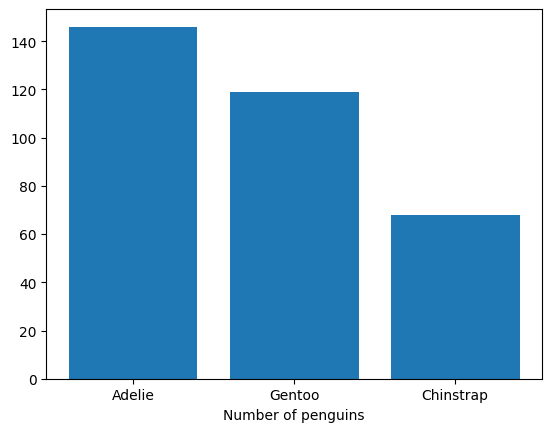

In [18]:
# 4.1 Draw a bar chart of the number of penguins per species.
counts = df_clean["species"].value_counts()
plt.bar(counts.index, counts.values)
plt.xlabel("Species")
plt.xlabel("Number of penguins")
plt.show()



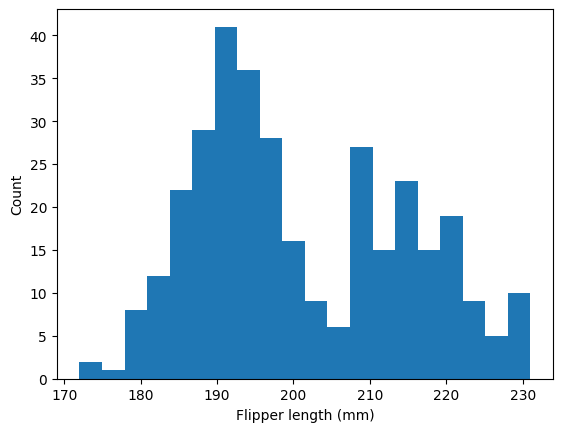

In [20]:
# 4.2 Draw a histogram of flipper length with 20 bins. Label the axes.

plt.hist(df_clean["flipper_length_mm"], bins=20)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Count")
plt.show()


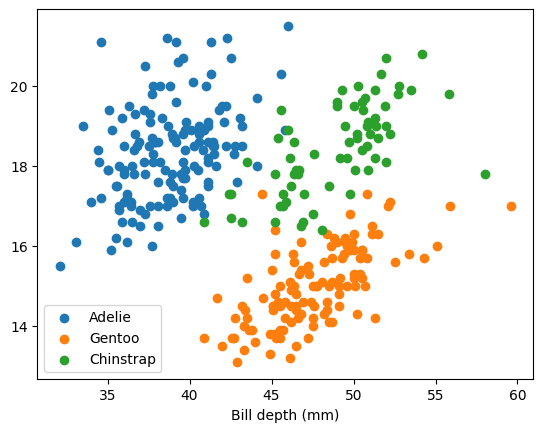

In [24]:
# 4.3 Draw a scatter plot of bill length (x) against bill depth (y), with one colour per species and a legend.


for s in df_clean["species"].unique():
    part = df_clean[df_clean["species"] == s]
    plt.scatter(part["bill_length_mm"], part["bill_depth_mm"], label=s)
plt.xlabel("Bill length (mm)")
plt.xlabel("Bill depth (mm)")
plt.legend()
plt.show()

**4.4 In a markdown cell: look at your histogram and scatter plot. What do you notice? Which data mining task could use these patterns?**

*Write your answer here.*

I can see that the flipper length aroind 190 to 200 has a much higher count at its highest peak where the others havent much lower but it does go up and down

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 4: charts"
git push
</pre>

## Part 5: Always Plot Your Data

In [25]:
# 5.1 Load `anscombe.csv`. For each dataset (I to IV), calculate the mean and variance of x and y.

ans = pd.read_csv("anscombe.csv")
ans.groupby("dataset")[["x","y"]].agg(["mean","var"]).round(2)


x          y      
        mean   var mean   var
dataset                      
I        9.0  11.0  7.5  4.13
II       9.0  11.0  7.5  4.13
III      9.0  11.0  7.5  4.12
IV       9.0  11.0  7.5  4.12

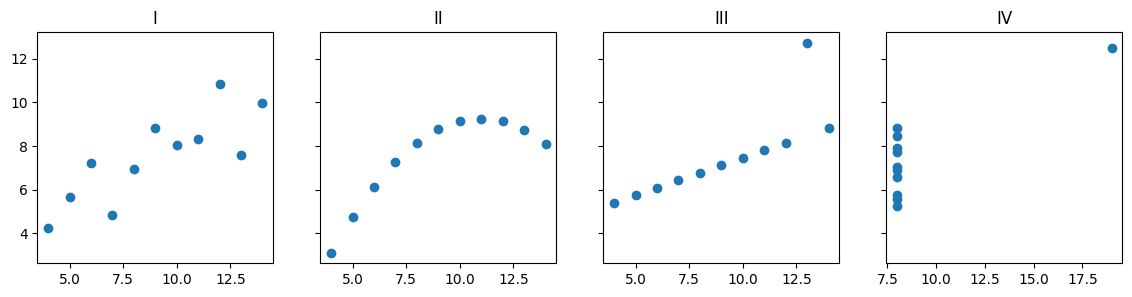

In [30]:
# 5.2 Draw the four datasets as four scatter plots side by side.

fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (name, part) in zip(axes, ans.groupby("dataset")):
    ax.scatter(part["x"], part["y"])
    ax.set_title(name)
plt.show()
        


**5.3 In a markdown cell: what is the lesson of this part?**

*Write your answer here.*

THe graphs

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 5: Anscombe's quartet"
git push
</pre>